# Modelo: Árvore de Decisão (Decision Tree)
**Dataset:** Sonar – Classificação de Minas vs Rochas  
**Algoritmo:** DecisionTreeClassifier (scikit-learn)  
**Critério:** Entropy | max_depth=5 | min_samples_leaf=2  
**Split:** 75% treino / 25% teste | random_state=42


## 1. Importações e Configuração

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay
)
# Bibliotecas de monitoramento de performance computacional
import time
import tracemalloc
import platform
import psutil
import os

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120


## 2. Carregamento dos Dados

In [14]:
PATH = r"../sonar_data_matriz.csv"

dataset = pd.read_csv(PATH, header=None)
print("Shape:", dataset.shape)
print("\nDistribuição de classes (original):")
print(dataset.iloc[:, -1].value_counts())
dataset.head()


Shape: (208, 61)

Distribuição de classes (original):
60
M    111
R     97
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


## 3. Pré-processamento

In [15]:
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

# Codificação: M=1 (Mina), R=0 (Rocha)
y = np.where(y == 'M', 1, 0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print(f"Treino : {X_train.shape[0]} amostras")
print(f"Teste  : {X_test.shape[0]} amostras")
print(f"Classes: 0=Rocha, 1=Mina")


Treino : 156 amostras
Teste  : 52 amostras
Classes: 0=Rocha, 1=Mina


## 4. Treinamento do Modelo

In [16]:
modelo = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_leaf=2,
    random_state=42
)

modelo.fit(X_train, y_train)
y_pred  = modelo.predict(X_test)
y_proba = modelo.predict_proba(X_test)[:, 1]

print("Modelo treinado com sucesso")


Modelo treinado com sucesso


## 5. Métricas de Desempenho

In [17]:
acc       = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
roc_auc   = roc_auc_score(y_test, y_proba)
cv_scores = cross_val_score(modelo, X, y, cv=5, scoring='accuracy')

metricas = {
    "Acurácia"         : acc,
    "Precisão (Mina)"  : precision,
    "Recall (Mina)"    : recall,
    "F1-Score (Mina)"  : f1,
    "ROC-AUC"          : roc_auc,
    "CV Acurácia (5x)" : cv_scores.mean(),
}

df_metricas = pd.DataFrame(metricas.items(), columns=["Métrica", "Valor"])
df_metricas["Valor"] = df_metricas["Valor"].map(lambda v: f"{v:.4f}")
print("=== MÉTRICAS – ÁRVORE DE DECISÃO ===")
display(df_metricas)


=== MÉTRICAS – ÁRVORE DE DECISÃO ===


,Métrica,Valor
0,Acurácia,0.8462
1,Precisão (Mina),0.9231
2,Recall (Mina),0.8000
3,F1-Score (Mina),0.8571
4,ROC-AUC,0.8621
5,CV Acurácia (5x),0.6110


## 6. Performance Computacional

Métricas de uso de CPU, memória RAM e tempo de execução coletadas durante o treinamento e a inferência do modelo.


In [18]:
# Informações do ambiente
print("=== AMBIENTE DE EXECUÇÃO ===")
print(f"  SO          : {platform.system()} {platform.release()}")
print(f"  Processador : {platform.processor() or platform.machine()}")
print(f"  Núcleos CPU : {psutil.cpu_count(logical=False)} físicos / {psutil.cpu_count()} lógicos")
print(f"  RAM total   : {psutil.virtual_memory().total / 1e9:.2f} GB")
print(f"  Python      : {platform.python_version()}")

# CPU e RAM antes do treino
cpu_antes = psutil.cpu_percent(interval=0.5)
proc      = psutil.Process(os.getpid())
ram_antes = proc.memory_info().rss / 1e6  # MB

# Treino com medição de tempo e memória 
tracemalloc.start()
t0_treino = time.perf_counter()

_modelo_perf = DecisionTreeClassifier(
    criterion='entropy', max_depth=5, min_samples_leaf=2, random_state=42
)
_modelo_perf.fit(X_train, y_train)

t1_treino = time.perf_counter()
mem_pico_treino, _ = tracemalloc.get_traced_memory()
tracemalloc.stop()

tempo_treino       = t1_treino - t0_treino
mem_pico_treino_mb = mem_pico_treino / 1e6

# Inferência com medição de tempo
t0_inf = time.perf_counter()
_ = _modelo_perf.predict(X_test)
t1_inf = time.perf_counter()
tempo_inferencia  = t1_inf - t0_inf
tempo_por_amostra = tempo_inferencia / len(X_test) * 1000  # ms

# CPU e RAM depois 
cpu_depois = psutil.cpu_percent(interval=0.5)
ram_depois = proc.memory_info().rss / 1e6

# Tabela de resultados 
df_perf = pd.DataFrame({
    "Métrica": [
        "Tempo de Treino (s)",
        "Tempo de Inferência (s)",
        "Tempo por Amostra (ms)",
        "Pico de Memória — Treino (MB)",
        "RAM do Processo — Antes (MB)",
        "RAM do Processo — Depois (MB)",
        "Delta RAM (MB)",
        "CPU antes do treino (%)",
        "CPU depois do treino (%)",
        "Amostras de Treino",
        "Amostras de Teste",
        "Núcleos lógicos disponíveis",
    ],
    "Valor": [
        f"{tempo_treino:.6f}",
        f"{tempo_inferencia:.6f}",
        f"{tempo_por_amostra:.4f}",
        f"{mem_pico_treino_mb:.4f}",
        f"{ram_antes:.2f}",
        f"{ram_depois:.2f}",
        f"{ram_depois - ram_antes:.2f}",
        f"{cpu_antes:.1f}",
        f"{cpu_depois:.1f}",
        str(len(X_train)),
        str(len(X_test)),
        str(psutil.cpu_count()),
    ]
})

print("\n=== PERFORMANCE COMPUTACIONAL — ÁRVORE DE DECISÃO ===")
display(df_perf)


=== AMBIENTE DE EXECUÇÃO ===
  SO          : Windows 10
  Processador : AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD
  Núcleos CPU : 6 físicos / 12 lógicos
  RAM total   : 16.53 GB
  Python      : 3.11.9

=== PERFORMANCE COMPUTACIONAL — ÁRVORE DE DECISÃO ===


,Métrica,Valor
0,Tempo de Treino (s),0.007860
1,Tempo de Inferência (s),0.000148
2,Tempo por Amostra (ms),0.0029
3,Pico de Memória — Treino (MB),0.0032
4,RAM do Processo — Antes (MB),279.58
5,RAM do Processo — Depois (MB),276.28
6,Delta RAM (MB),-3.31
7,CPU antes do treino (%),7.9
8,CPU depois do treino (%),6.8
9,Amostras de Treino,156


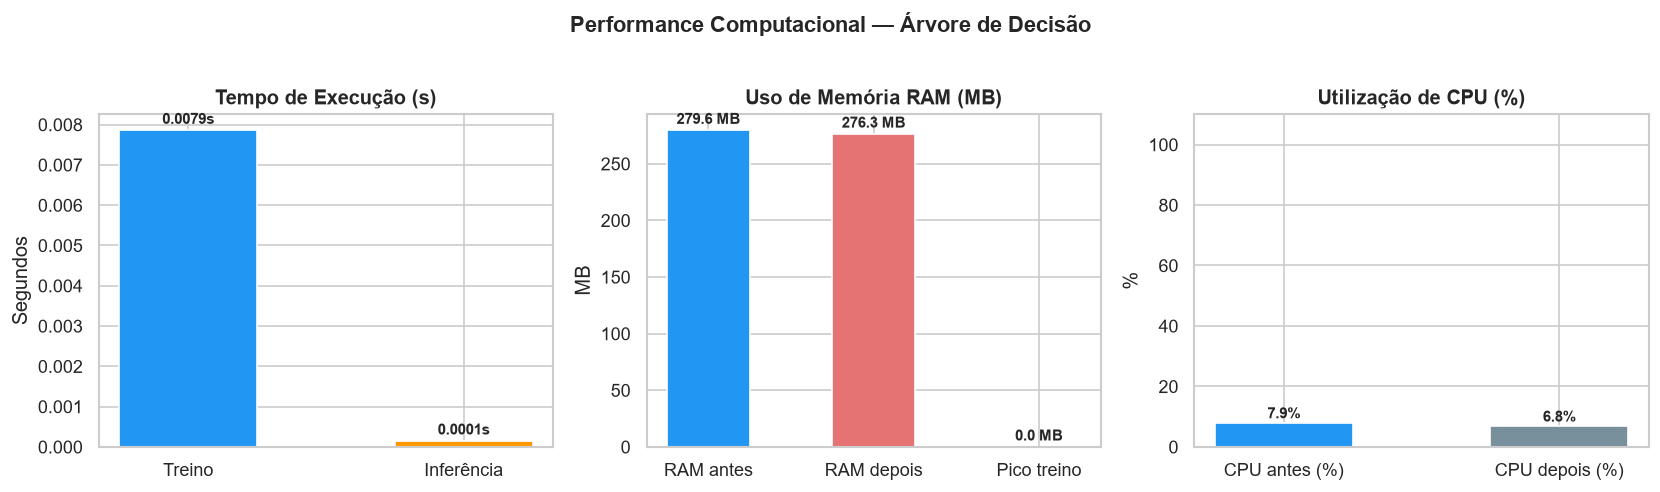

In [19]:
# ── Visualização das métricas de performance ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Tempo
labels_t = ["Treino", "Inferência"]
vals_t   = [tempo_treino, tempo_inferencia]
bars = axes[0].bar(labels_t, vals_t, color=["#2196F3", "#FF9800"], edgecolor="white", width=0.5)
for b, v in zip(bars, vals_t):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + max(vals_t)*0.01,
                 f"{v:.4f}s", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_title("Tempo de Execução (s)", fontweight="bold")
axes[0].set_ylabel("Segundos")

# 2. Memória RAM
labels_m = ["RAM antes", "RAM depois", "Pico treino"]
vals_m   = [ram_antes, ram_depois, mem_pico_treino_mb]
bars = axes[1].bar(labels_m, vals_m, color=["#2196F3", "#E57373", "#FFB74D"], edgecolor="white", width=0.5)
for b, v in zip(bars, vals_m):
    axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + max(vals_m)*0.01,
                 f"{v:.1f} MB", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[1].set_title("Uso de Memória RAM (MB)", fontweight="bold")
axes[1].set_ylabel("MB")

# 3. CPU
labels_c = ["CPU antes (%)", "CPU depois (%)"]
vals_c   = [cpu_antes, cpu_depois]
bars = axes[2].bar(labels_c, vals_c, color=["#2196F3", "#78909C"], edgecolor="white", width=0.5)
for b, v in zip(bars, vals_c):
    axes[2].text(b.get_x() + b.get_width()/2, b.get_height() + 0.5,
                 f"{v:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[2].set_ylim(0, 110)
axes[2].set_title("Utilização de CPU (%)", fontweight="bold")
axes[2].set_ylabel("%")

fig.suptitle("Performance Computacional — Árvore de Decisão", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


## 7. Matriz de Confusão

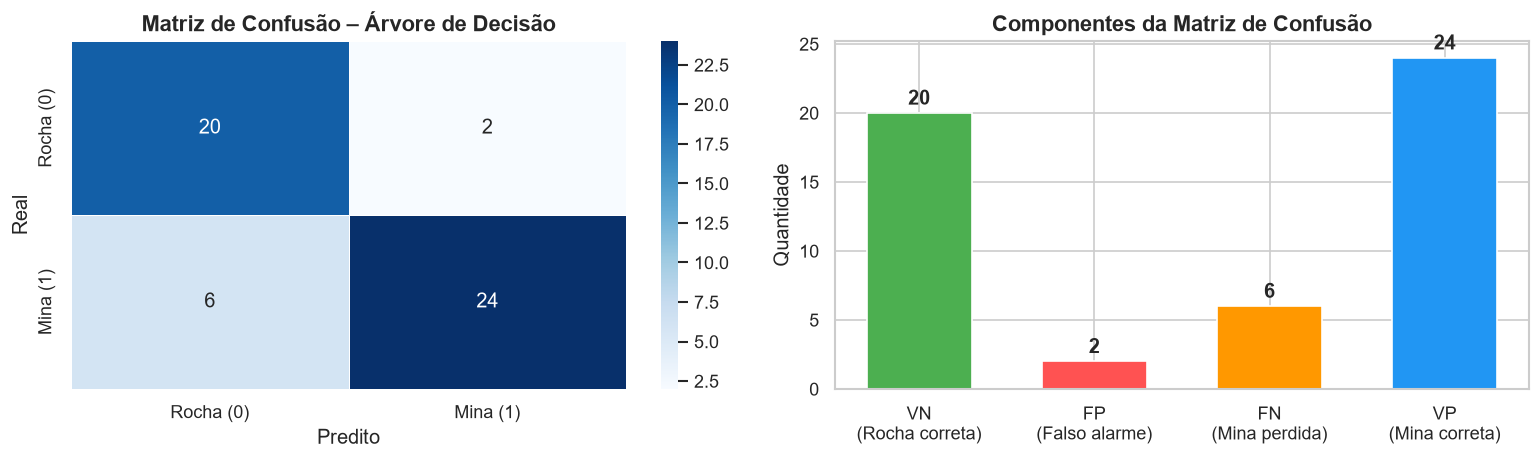


VN=20  FP=2  FN=6  VP=24


In [20]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rocha (0)', 'Mina (1)'],
            yticklabels=['Rocha (0)', 'Mina (1)'],
            ax=axes[0], linewidths=.5)
axes[0].set_title('Matriz de Confusão – Árvore de Decisão', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Real')
axes[0].set_xlabel('Predito')

# Barras de componentes
labels = ['VN\n(Rocha correta)', 'FP\n(Falso alarme)', 'FN\n(Mina perdida)', 'VP\n(Mina correta)']
values = [cm[0,0], cm[0,1], cm[1,0], cm[1,1]]
colors = ['#4CAF50', '#FF5252', '#FF9800', '#2196F3']
bars = axes[1].bar(labels, values, color=colors, edgecolor='white', width=0.6)
for bar, val in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(val), ha='center', va='bottom', fontweight='bold')
axes[1].set_title('Componentes da Matriz de Confusão', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Quantidade')

plt.tight_layout()
plt.savefig('../images/decision_tree/arvore_matriz_confusao.png', bbox_inches='tight')
plt.show()

print(f"\nVN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  VP={cm[1,1]}")


## 8. Relatório de Classificação Completo

In [21]:
print(classification_report(y_test, y_pred, target_names=["Rocha (0)", "Mina (1)"]))


              precision    recall  f1-score   support

   Rocha (0)       0.77      0.91      0.83        22
    Mina (1)       0.92      0.80      0.86        30

    accuracy                           0.85        52
   macro avg       0.85      0.85      0.85        52
weighted avg       0.86      0.85      0.85        52



## 9. Validação Cruzada (5-fold)

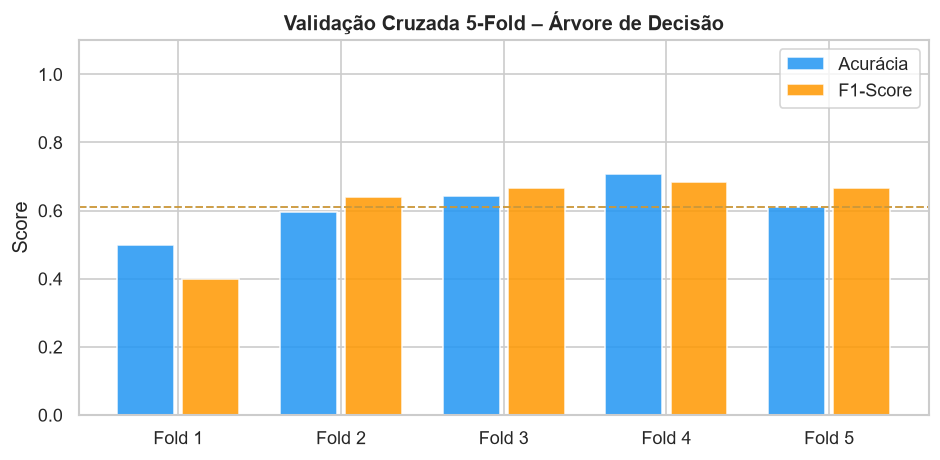

Acurácia CV  → média=0.6110  std=0.0676
F1-Score CV  → média=0.6112   std=0.1066


In [22]:
cv_acc = cross_val_score(modelo, X, y, cv=5, scoring='accuracy')
cv_f1  = cross_val_score(modelo, X, y, cv=5, scoring='f1')

fig, ax = plt.subplots(figsize=(8, 4))
folds = [f'Fold {i+1}' for i in range(5)]
x = np.arange(5)
ax.bar(x - 0.2, cv_acc, 0.35, label='Acurácia', color='#2196F3', alpha=0.85)
ax.bar(x + 0.2, cv_f1,  0.35, label='F1-Score',  color='#FF9800', alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(folds)
ax.set_ylim(0, 1.1); ax.set_ylabel('Score')
ax.set_title('Validação Cruzada 5-Fold – Árvore de Decisão', fontweight='bold')
ax.legend(); ax.axhline(cv_acc.mean(), color='#2196F3', ls='--', lw=1.2, alpha=0.7)
ax.axhline(cv_f1.mean(),  color='#FF9800',  ls='--', lw=1.2, alpha=0.7)
plt.tight_layout()
plt.savefig('../images/decision_tree/arvore_cv.png', bbox_inches='tight')
plt.show()

print(f"Acurácia CV  → média={cv_acc.mean():.4f}  std={cv_acc.std():.4f}")
print(f"F1-Score CV  → média={cv_f1.mean():.4f}   std={cv_f1.std():.4f}")


## 10. Sumário Final

In [23]:
resultados_modelo = pd.DataFrame({
    "Modelo"          : ["Árvore de Decisão"],
    "Acurácia"        : [round(acc, 4)],
    "Precisão"        : [round(precision, 4)],
    "Recall"          : [round(recall, 4)],
    "F1-Score"        : [round(f1, 4)],
    "ROC-AUC"         : [round(roc_auc, 4)],
    "CV Acurácia (μ)" : [round(cv_scores.mean(), 4)],
})

dados_processamento = pd.DataFrame({
    "Tempo Treino (s)"         : [round(tempo_treino, 6)],
    "Tempo Inferência (s)"     : [round(tempo_inferencia, 6)],
    "Tempo/Amostra (ms)"       : [round(tempo_por_amostra, 4)],
    "Pico Memória Treino (MB)" : [round(mem_pico_treino_mb, 4)],
    "Delta RAM (MB)"           : [round(ram_depois - ram_antes, 2)],
})

print("=== RESULTADOS DO MODELO ===")
display(resultados_modelo)

print("=== DADOS DE PROCESSAMENTO ===")
display(dados_processamento)

resultados_modelo.to_csv("../results/decision_tree/resultados_modelo_arvore.csv", index=False)
dados_processamento.to_csv("../results/decision_tree/dados_processamento_arvore.csv", index=False)

print("Arquivos CSV gerados com sucesso!")

=== RESULTADOS DO MODELO ===


,Modelo,Acurácia,Precisão,Recall,F1-Score,ROC-AUC,CV Acurácia (μ)
0,Árvore de Decisão,0.8462,0.9231,0.8,0.8571,0.8621,0.611


=== DADOS DE PROCESSAMENTO ===


,Tempo Treino (s),Tempo Inferência (s),Tempo/Amostra (ms),Pico Memória Treino (MB),Delta RAM (MB)
0,0.00786,0.000148,0.0029,0.0032,-3.31


Arquivos CSV gerados com sucesso!


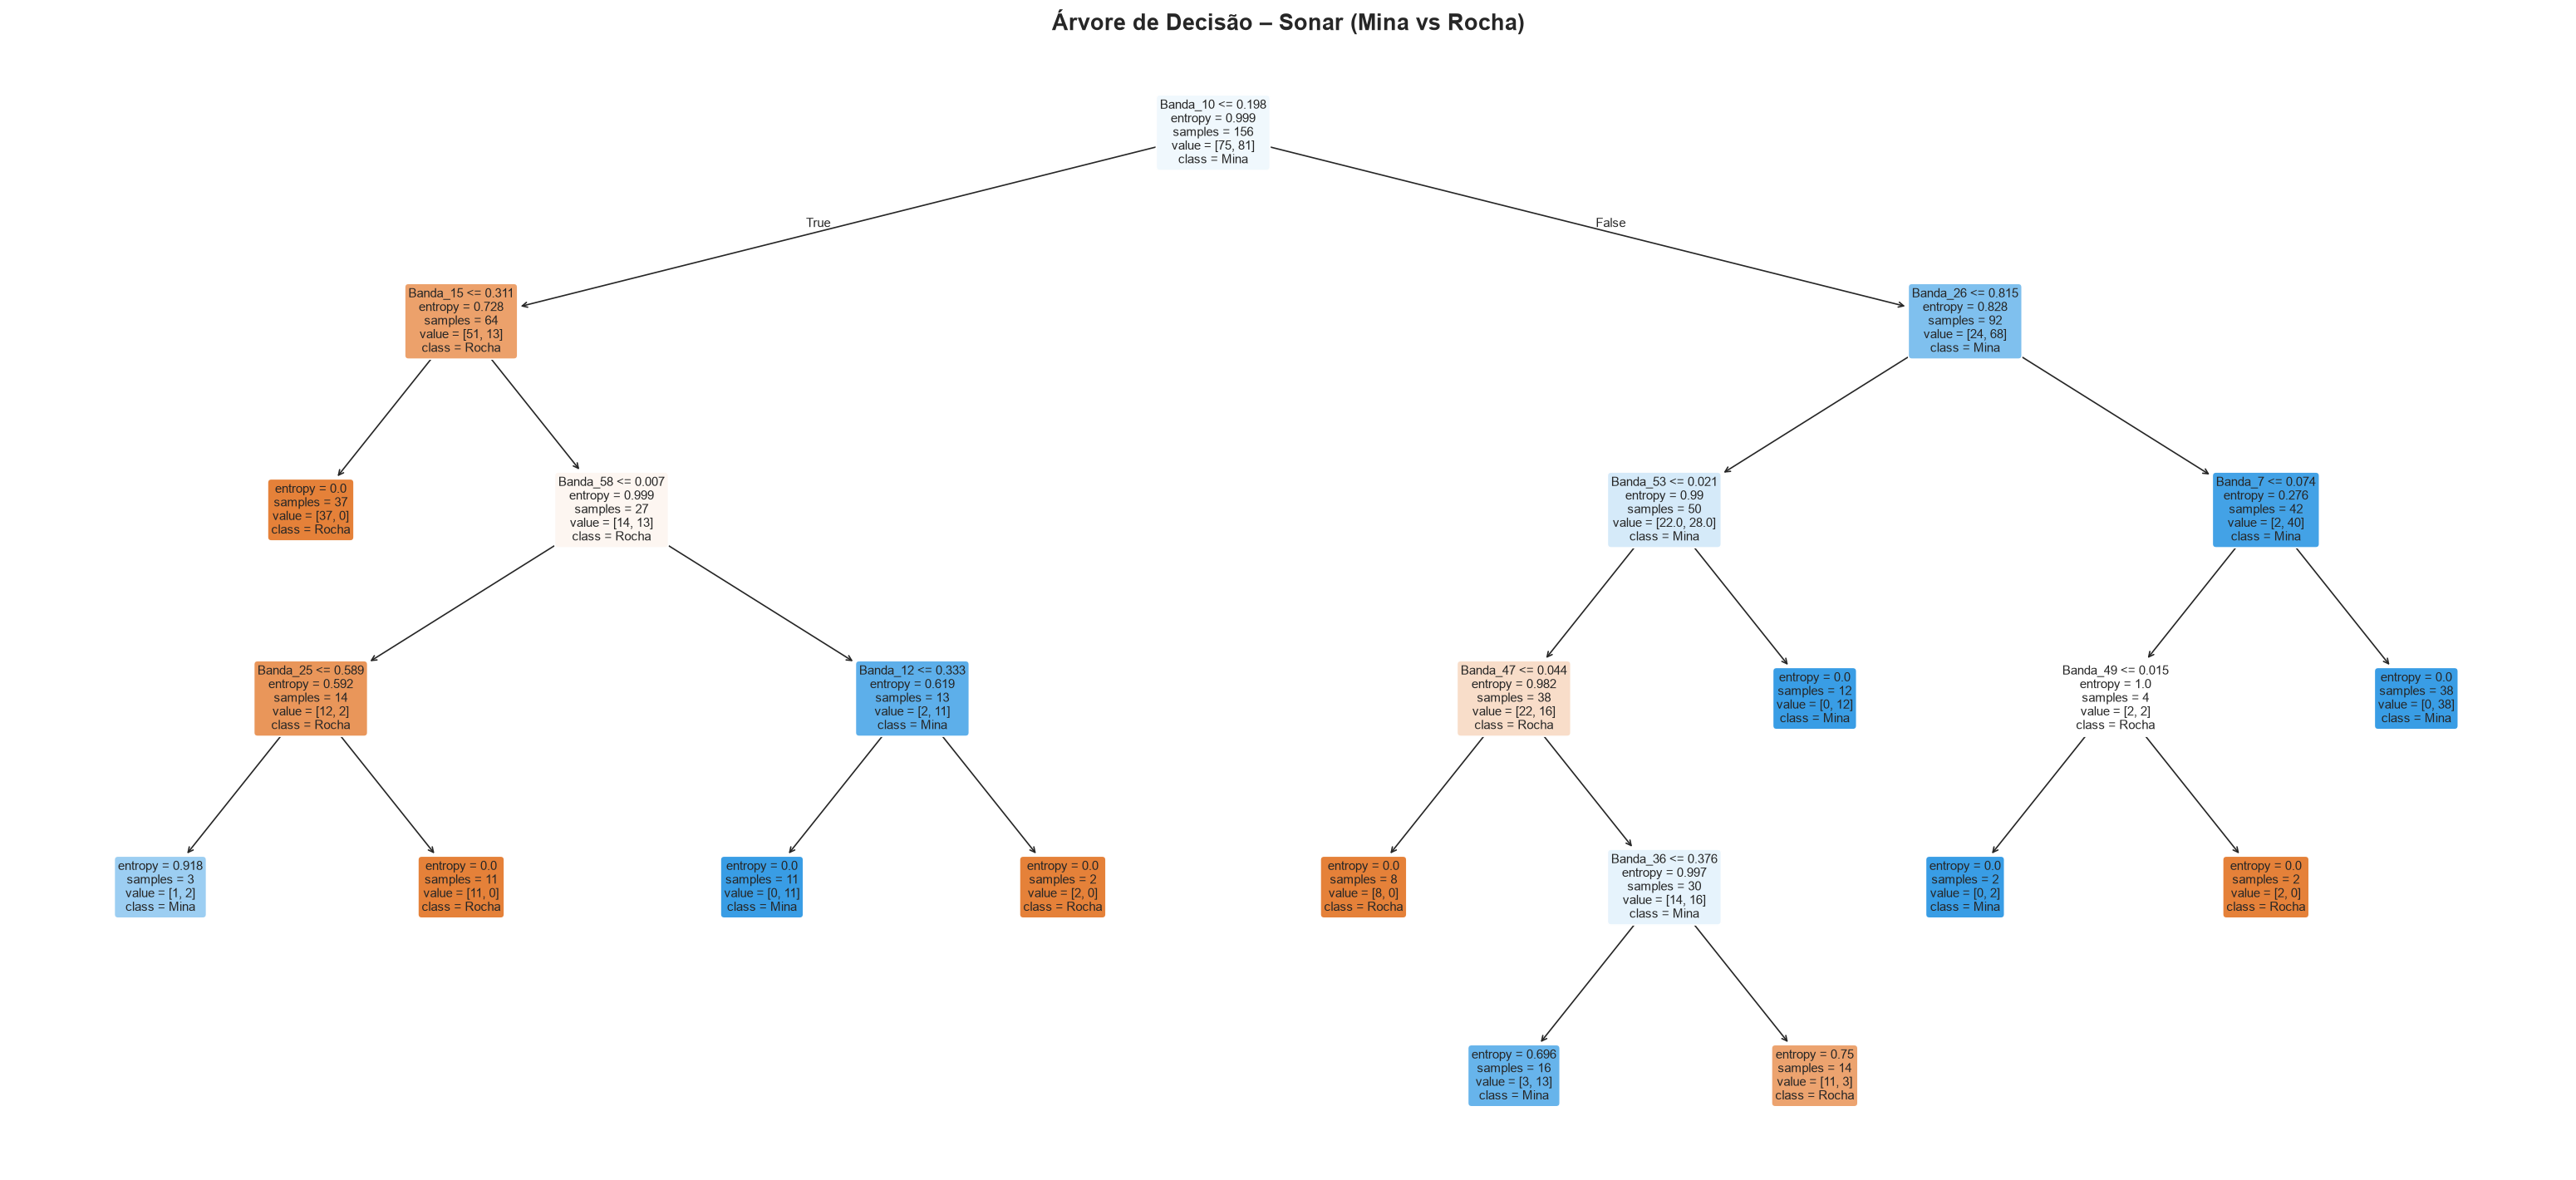

In [24]:
# ===== Gráfico da Árvore de Decisão (rodar DEPOIS da célula que treina o `modelo`) =====
from sklearn.tree import plot_tree, export_text

nomes_features = [f"Banda_{i}" for i in range(X.shape[1])]   # o sonar tem 60 bandas de frequência
nomes_classes  = ["Rocha", "Mina"]                            # 0 = Rocha, 1 = Mina

# --- 1) Árvore completa (nós coloridos pela classe; quanto mais forte a cor, mais "puro" o nó) ---
fig, ax = plt.subplots(figsize=(26, 12))
plot_tree(
    modelo,
    feature_names=nomes_features,
    class_names=nomes_classes,
    filled=True,        # cor por classe
    rounded=True,       # nós arredondados
    impurity=True,      # mostra a entropia do nó
    proportion=False,   # False = mostra nº de amostras; True = mostra proporções
    fontsize=9,
    ax=ax,
)
ax.set_title("Árvore de Decisão – Sonar (Mina vs Rocha)", fontsize=16, fontweight="bold")
plt.tight_layout()
os.makedirs("../images/decision_tree", exist_ok=True)
plt.savefig("../images/decision_tree/arvore_decisao.png", dpi=150, bbox_inches="tight")
plt.show()